# Detecting phishing from webpage screenshots

**AI in Cybersecurity capstone · Python implementation**

Can a model flag a phishing webpage from its screenshot? This experiment compares a traditional visual signature rule, three classical machine-learning algorithms, and three deep-learning architectures on the same labeled screenshots. Every detector uses image content. URLs, HTML, filenames, and brand labels are excluded from the model inputs.

**Present the experiment.** The saved notebook outputs are ready to show. For a live demo, start Jupyter in the project folder and run the setup, configuration, model helpers and quick-demo cells below in order. The bundled screenshot and saved Compact CNN are in `phish_iris_run/`. The benchmark screenshot scores approximately 0.783 at a cutoff of 0.55.

**Reproduce the benchmark.** Choose **Run All**. The bundled 25 MB input cache lets the notebook reproduce the dataset split and train the detectors without downloading the screenshot archive. Keep `phish_iris_run/` next to the notebook. If you open the notebook outside that folder or remove the cache, set `LOCAL_ARCHIVE` to a local Phish-IRIS ZIP or allow the approximately 799 MB download. The setup cell installs any missing packages into the active kernel.

**Code walkthrough.** Section 2 covers preprocessing and duplicate controls. Section 5 defines and trains the neural detectors using the model helpers below. Section 7 applies Grad-CAM and occlusion. Section 9 runs inference with the newly trained model and exports the experiment results.

In [1]:
# The setup cell installs only missing libraries into the active Jupyter kernel.
import importlib.util
import subprocess
import sys

packages = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "PIL": "Pillow", "sklearn": "scikit-learn", "torch": "torch",
    "joblib": "joblib", "jinja2": "Jinja2",
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

In [2]:
import hashlib
import http.client
import io
import json
import os
import random
import shutil
import time
import urllib.request
import zipfile
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path, PurePosixPath

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
IMAGE_SIDE = 96
MAX_EPOCHS = 14
PATIENCE = 4
BATCH_SIZE = 48
LOCAL_ARCHIVE = None  # Example: Path("Phish-irish.zip")
RUN_DIR = Path(os.environ.get("PHISH_IRIS_RUN_DIR", "phish_iris_run")).resolve()
DATA_URL = "https://zenodo.org/records/23477065/files/Phish-irish.zip?download=1"
RANGE_URL = "https://zenodo.org/api/records/23477065/files/Phish-irish.zip/content"
ARCHIVE_SIZE = 798_950_585
ARCHIVE_MD5 = "114b6281fdde20f41dbac34c382b2442"  # Publisher's checksum
RUN_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CPU_THREADS = min(4, os.cpu_count() or 1)
torch.set_num_threads(CPU_THREADS)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "font.size": 10,
})
CLASS_NAMES = ["Legitimate", "Phishing"]
COLORS = ["#177E89", "#D25544"]
versions = {
    "python": sys.version.split()[0], "torch": str(torch.__version__),
    "scikit-learn": sklearn.__version__, "numpy": np.__version__,
    "pandas": pd.__version__, "device": str(DEVICE),
}
print(versions)

{'python': '3.14.6', 'torch': '2.12.1+cpu', 'scikit-learn': '1.9.0', 'numpy': '2.5.5', 'pandas': '3.0.3', 'device': 'cpu'}


## Quick demo using the saved CNN checkpoint

This cell loads the bundled `selected_cnn.pt`, so it runs without retraining. It expects `Demo_Screenshot.png` in `phish_iris_run/`.


In [3]:
# Shared screenshot preprocessing and CNN architecture

def to_rgb(image):
    image = ImageOps.exif_transpose(image)
    if "A" in image.getbands() or "transparency" in image.info:
        rgba = image.convert("RGBA")
        white = Image.new("RGBA", rgba.size, "white")
        return Image.alpha_composite(white, rgba).convert("RGB")
    return image.convert("RGB")


def as_model_image(rgb):
    return np.asarray(rgb.resize((IMAGE_SIDE, IMAGE_SIDE), Image.Resampling.BILINEAR))


def convolution(in_channels, out_channels, stride=1):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
    )


class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.body = nn.Sequential(
            convolution(in_channels, out_channels, stride=2),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
        )
        self.skip = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 1, stride=2, bias=False),
            nn.BatchNorm2d(out_channels),
        )

    def forward(self, x):
        return F.relu(self.body(x) + self.skip(x))


class ScreenshotCNN(nn.Module):
    def __init__(self, dropout, residual=False):
        super().__init__()
        if residual:
            self.encoder = nn.Sequential(
                convolution(3, 12, stride=2),
                ResidualBlock(12, 16), ResidualBlock(16, 24), ResidualBlock(24, 48),
            )
            channels = 48
        else:
            self.encoder = nn.Sequential(
                convolution(3, 16, stride=2), nn.MaxPool2d(2),
                convolution(16, 24), nn.MaxPool2d(2), convolution(24, 40),
            )
            channels = 40
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((4, 4)), nn.Flatten(),
            nn.Linear(channels * 16, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1),
        )

    def classify_features(self, feature_maps):
        return self.classifier(feature_maps).squeeze(1)

    def forward(self, x):
        return self.classify_features(self.encoder(x))


def to_tensor(images):
    return torch.from_numpy(np.ascontiguousarray(images.transpose(0, 3, 1, 2))).float() / 255

In [4]:
QUICK_DEMO_IMAGE = RUN_DIR / "Demo_Screenshot.png"


def score_saved_cnn(image_path, checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    if checkpoint["name"] not in {"Compact CNN", "Residual CNN"} or checkpoint["image_side"] != IMAGE_SIDE:
        raise ValueError("The checkpoint must be a supported CNN for this image size.")
    model = ScreenshotCNN(
        checkpoint["dropout"], residual=checkpoint["name"] == "Residual CNN"
    ).eval()
    model.load_state_dict(checkpoint["state_dict"])
    with Image.open(image_path) as image:
        pixels = as_model_image(to_rgb(image))
    with torch.inference_mode():
        score = model(to_tensor(pixels[None])).sigmoid().item()
    cutoff = checkpoint["threshold"]
    return checkpoint["name"], score, cutoff, CLASS_NAMES[int(score >= cutoff)]


checkpoint_path = RUN_DIR / "selected_cnn.pt"
if QUICK_DEMO_IMAGE.is_file() and checkpoint_path.is_file():
    model_name, score, cutoff, prediction = score_saved_cnn(QUICK_DEMO_IMAGE, checkpoint_path)
    print(f"{model_name}: {prediction} (score {score:.3f}, cutoff {cutoff:.2f})")
else:
    print("For the quick demo, open the notebook from the project folder with its bundled files.")
    print("Run the notebook from the start to train a model for section 9.")


Compact CNN: Phishing (score 0.783, cutoff 0.55)


## 1 · Traditional and AI-driven detection

| Approach | How it makes a decision | Operational trade-off |
|---|---|---|
| Signature matching | Compares an observation with known threat patterns. Here the signatures are perceptual hashes of known phishing screenshots. | Easy to trace to a match and update by adding signatures. Coverage depends on the reference library. |
| Rule-based detection | Applies an explicit condition to evidence, such as whether a visual distance falls within a fixed cutoff. | Analysts can review the rule directly. Different websites can produce similar signals. |
| Anomaly detection | Compares an observation with a learned or configured profile of normal activity. | Can surface novel activity. Legitimate changes can also trigger alerts. |
| Supervised ML and DL | Learn patterns from labeled examples. Classical ML sees hand-engineered visual measurements. Deep models learn from resized RGB pixels. | Can generalize beyond exact matches, with performance dependent on training coverage and data quality. |

The hash baseline combines a reference signature library with an explicit decision rule. Anomaly detection is included in the literature comparison. Dalgic et al. used color and edge descriptors to analyze phishing screenshots. Phishpedia used webpage logos and legitimate brand references to support visual phishing identification. This experiment tests binary screenshot screening. [NIST SP 800-94](https://csrc.nist.gov/pubs/sp/800/94/final) · [Phish-IRIS paper](https://arxiv.org/abs/1905.07767) · [Phishpedia](https://www.usenix.org/conference/usenixsecurity21/presentation/lin)

## 2 · Dataset, label encoding and cleaning

Phish-IRIS was collected from March to May 2018 for visual phishing research. Its companion paper reports 2,852 screenshots and 14 phishing brand categories. This notebook uses a Zenodo mirror organized by category and measures the actual archive contents. The category folder `other` is encoded as **0 (legitimate)** and each phishing brand folder as **1 (phishing)**. The categories describe targets of impersonation. [Original dataset record](https://data.mendeley.com/datasets/tk4fkswtj5/1) · [Zenodo mirror](https://zenodo.org/records/23477065)

Screenshots provide visual evidence such as layout, color and edges. They cannot confirm whether a page controls a brand's domain or what happens after a form submission. The notebook reads image entries directly from the ZIP, converts them to RGB and resizes each to 96 × 96 with bilinear resampling. The fixed square compresses wide layouts but preserves the full screenshot. Original width and height are recorded for the audit only.

**Leakage controls.** The mirror retains the original `_test` filename markers. These recover the published source split for all 14 phishing categories. The mirror contains three fewer legitimate screenshots than the original counts. Drop unreadable and near-uniform captures, remove exact-image groups with conflicting labels, and keep one copy of each remaining exact image, prioritizing source train. Group visually similar screenshots and exclude any test image whose group already occurs in source train. Split source train into train and validation by group. [Phish-IRIS project](https://web.cs.hacettepe.edu.tr/~selman/phish-iris-dataset/) · [Published class and split counts](https://arxiv.org/abs/1905.07767)

In [5]:
def digest_file(path, algorithm):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, algorithm).hexdigest()


def download_archive(destination):
    """Fetch and verify the pinned archive, retaining completed ranges for retry."""
    part_dir = destination.with_name(destination.stem + "_ranges")
    part_dir.mkdir(exist_ok=True)
    range_size = 16 * 1024 * 1024

    def download_range(start):
        end = min(start + range_size, ARCHIVE_SIZE) - 1
        piece = part_dir / f"{start:09}.part"
        required_bytes = end - start + 1
        if piece.exists() and piece.stat().st_size == required_bytes:
            return piece
        request = urllib.request.Request(
            RANGE_URL, headers={"Range": f"bytes={start}-{end}", "User-Agent": "Phish-IRIS-capstone/1.0"}
        )
        temporary_piece = piece.with_suffix(".partial")
        for attempt in range(3):
            try:
                with urllib.request.urlopen(request, timeout=65) as response:
                    if response.headers.get("Content-Range") != f"bytes {start}-{end}/{ARCHIVE_SIZE}":
                        raise OSError("The server returned a different byte range.")
                    with temporary_piece.open("wb") as out:
                        shutil.copyfileobj(response, out, length=256 * 1024)
                if temporary_piece.stat().st_size != required_bytes:
                    raise OSError("An archive range was incomplete.")
                temporary_piece.replace(piece)
                return piece
            except (OSError, http.client.HTTPException):
                if attempt == 2:
                    raise
                time.sleep(2 ** attempt)
            finally:
                temporary_piece.unlink(missing_ok=True)

    partial = destination.with_suffix(".zip.partial")
    try:
        with ThreadPoolExecutor(max_workers=6) as pool:
            pieces = list(pool.map(download_range, range(0, ARCHIVE_SIZE, range_size)))
        with partial.open("wb") as out:
            for piece in pieces:
                with piece.open("rb") as stream:
                    shutil.copyfileobj(stream, out, length=1024 * 1024)
        if digest_file(partial, "md5") != ARCHIVE_MD5:
            for piece in pieces:
                piece.unlink()
            raise ValueError("The downloaded archive failed the publisher's checksum.")
        partial.replace(destination)
        for piece in pieces:
            piece.unlink()
        part_dir.rmdir()
    except OSError as error:
        raise OSError(f"Download stopped. Retry this cell or download {DATA_URL} and set LOCAL_ARCHIVE.") from error
    finally:
        partial.unlink(missing_ok=True)


def get_archive():
    path = Path(LOCAL_ARCHIVE) if LOCAL_ARCHIVE else RUN_DIR / "Phish-irish.zip"
    if not path.exists():
        if LOCAL_ARCHIVE:
            raise FileNotFoundError(f"Set LOCAL_ARCHIVE to the downloaded Zenodo ZIP: {path}")
        print("Downloading the Phish-IRIS archive (approximately 799 MB)...", flush=True)
        download_archive(path)
        return path
    if digest_file(path, "md5") != ARCHIVE_MD5:
        raise ValueError(f"Wrong archive or corrupt download: {path}. Use the linked Zenodo ZIP.")
    return path


def image_signature(rgb):
    small = np.asarray(rgb.convert("L").resize((9, 8), Image.Resampling.BILINEAR))
    bits = np.packbits(small[:, 1:] > small[:, :-1])
    return int.from_bytes(bits.tobytes(), "big")


def read_screenshots(path):
    records, images, audit = [], [], Counter()
    extensions = {".png", ".jpg", ".jpeg", ".bmp", ".webp", ".gif"}
    with zipfile.ZipFile(path) as archive:
        for member in sorted(archive.namelist()):
            entry = PurePosixPath(member)
            if entry.suffix.lower() not in extensions or "__MACOSX" in entry.parts:
                continue
            if len(entry.parts) != 3 or entry.parts[0] != "Phish-irish":
                audit["images outside class folders"] += 1
                continue
            category = entry.parent.name.lower()
            label = int(category != "other")
            source_split = "test" if "_test" in entry.stem.lower() else "train"
            audit[f"archive · {source_split} · {CLASS_NAMES[label]}"] += 1
            try:
                with Image.open(io.BytesIO(archive.read(member))) as image:
                    rgb = to_rgb(image)
            except (OSError, ValueError, Image.DecompressionBombError, zipfile.BadZipFile):
                audit["unreadable images"] += 1
                continue
            reduced = as_model_image(rgb)
            if np.std(reduced.astype(np.float32), axis=(0, 1)).mean() < 3:
                audit["near-uniform images"] += 1
                continue
            pixel_hash = hashlib.sha256()
            pixel_hash.update(f"{rgb.width}x{rgb.height}:".encode())
            pixel_hash.update(rgb.tobytes())
            records.append({
                "category": category, "label": label, "source_split": source_split,
                "width": rgb.width, "height": rgb.height,
                "pixel_hash": pixel_hash.hexdigest(),
                "dhash": f"{image_signature(rgb):016x}",
            })
            images.append(reduced)
    if not records:
        raise ValueError("No screenshot entries were found in the expected archive folders.")
    return pd.DataFrame(records), np.stack(images), dict(audit)


# Store decoded thumbnails locally so reruns skip the original download and decode.
cache = RUN_DIR / f"thumbnails_{ARCHIVE_MD5[:8]}_{IMAGE_SIDE}px_v1.npz"
if not cache.exists():
    archive_path = get_archive()
    decoded, thumbnails, raw_audit = read_screenshots(archive_path)
    temporary_cache = cache.with_name(cache.stem + ".partial.npz")
    np.savez_compressed(temporary_cache, images=thumbnails,
                        metadata=decoded.to_json(orient="records"), audit=json.dumps(raw_audit))
    temporary_cache.replace(cache)
else:
    with np.load(cache, allow_pickle=False) as contents:
        thumbnails = contents["images"]
        decoded = pd.DataFrame(json.loads(contents["metadata"].item()))
        raw_audit = json.loads(contents["audit"].item())

assert set(decoded.label) == {0, 1}
assert decoded.category.nunique() == 15, "Expected 14 brand folders and 'other'."
assert sum(count for name, count in raw_audit.items() if name.startswith("archive · test")) == 1537
assert sum(count for name, count in raw_audit.items() if name.startswith("archive · train")) == 1312
print(f"Decoded {len(decoded):,} usable screenshots before deduplication.")
display(pd.Series(raw_audit, name="images").to_frame())

Decoded 2,849 usable screenshots before deduplication.


,images
archive · train · Phishing,913
archive · test · Phishing,539
archive · train · Legitimate,399
archive · test · Legitimate,998


In [6]:
data_audit = dict(raw_audit)
conflicts = decoded.groupby("pixel_hash").label.transform("nunique").gt(1)
data_audit["removed: exact image with conflicting labels"] = int(conflicts.sum())
unique = decoded.loc[~conflicts].sort_values("source_split", ascending=False, kind="stable")
duplicates = unique.duplicated("pixel_hash")
data_audit["removed: repeated exact image"] = int(duplicates.sum())
eligible = np.sort(unique.index[~duplicates].to_numpy())
y = decoded.label.to_numpy(dtype=np.int64)
signatures = [int(value, 16) for value in decoded.dhash]
small_rgb = np.stack([
    np.asarray(Image.fromarray(image).resize((12, 12), Image.Resampling.BOX))
    for image in thumbnails
]).astype(np.float32) / 255.0


def near_duplicate_groups(indices):
    """Join screenshots within 5 dHash bits and 0.055 RGB thumbnail RMSE."""
    parent = {index: index for index in indices}

    def root(index):
        while parent[index] != index:
            parent[index] = parent[parent[index]]
            index = parent[index]
        return index

    for position, index in enumerate(indices):
        possible = [
            other for other in indices[:position]
            if (signatures[index] ^ signatures[other]).bit_count() <= 5
        ]
        if possible:
            distance = np.mean((small_rgb[possible] - small_rgb[index]) ** 2, axis=(1, 2, 3)) ** 0.5
            for other, difference in zip(possible, distance):
                if difference <= 0.055:
                    parent[root(other)] = root(index)
    return np.asarray([root(index) for index in indices])


groups = near_duplicate_groups(eligible)
group_counts = pd.Series(groups).value_counts()
data_audit["screenshots in multi-image groups"] = int(group_counts[group_counts > 1].sum())
data_audit["largest near-duplicate group"] = int(group_counts.max())
group_by_image = pd.Series(groups, index=eligible, name="group")
from_source_train = decoded.loc[eligible, "source_split"].eq("train").to_numpy()
development = eligible[from_source_train]
test_candidates = eligible[~from_source_train]
development_groups = groups[from_source_train]
test_idx = test_candidates[~np.isin(groups[~from_source_train], development_groups)]
data_audit["removed: test images in train visual groups"] = len(test_candidates) - len(test_idx)
validation_splitter = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train, validation = next(validation_splitter.split(development, y[development], development_groups))

splits = {
    "Train": np.sort(development[train]),
    "Validation": np.sort(development[validation]),
    "Test": np.sort(test_idx),
}
train_idx, val_idx, test_idx = splits.values()
all_indices = np.concatenate(list(splits.values()))
assert len(np.unique(all_indices)) == len(all_indices)
assert decoded.loc[all_indices, "pixel_hash"].is_unique
assert decoded.loc[test_idx, "source_split"].eq("test").all()
assert sum(group_by_image.loc[indices].nunique() for indices in splits.values()) == (
    group_by_image.loc[all_indices].nunique()
)
assert all(set(y[indices]) == {0, 1} for indices in splits.values())

split_counts = pd.DataFrame({
    name: np.bincount(y[indices], minlength=2) for name, indices in splits.items()
}, index=CLASS_NAMES).T.rename_axis("partition")
split_counts["Total"] = split_counts.sum(axis=1)
split_counts["Phishing share"] = split_counts["Phishing"] / split_counts["Total"]
display(pd.Series(data_audit, name="images").to_frame())
display(split_counts.style.format({"Phishing share": "{:.1%}"}))

,images
archive · train · Phishing,913
archive · test · Phishing,539
archive · train · Legitimate,399
archive · test · Legitimate,998
removed: exact image with conflicting labels,0
removed: repeated exact image,401
screenshots in multi-image groups,270
largest near-duplicate group,58
removed: test images in train visual groups,63


,Legitimate,Phishing,Total,Phishing share
partition,,,,
Train,299,544,843,64.5%
Validation,100,182,282,64.5%
Test,970,290,1260,23.0%


### What the split measures

The validation split takes about a quarter of source train while keeping each visual group intact. Training fits models, validation chooses configurations and score cutoffs, and the cleaned source test split evaluates those choices. The grouping is heuristic. The archive provides no domain or campaign identifiers, so visually different pages from the same campaign may still appear across splits. The 2018 collection also limits what these results say about current websites.

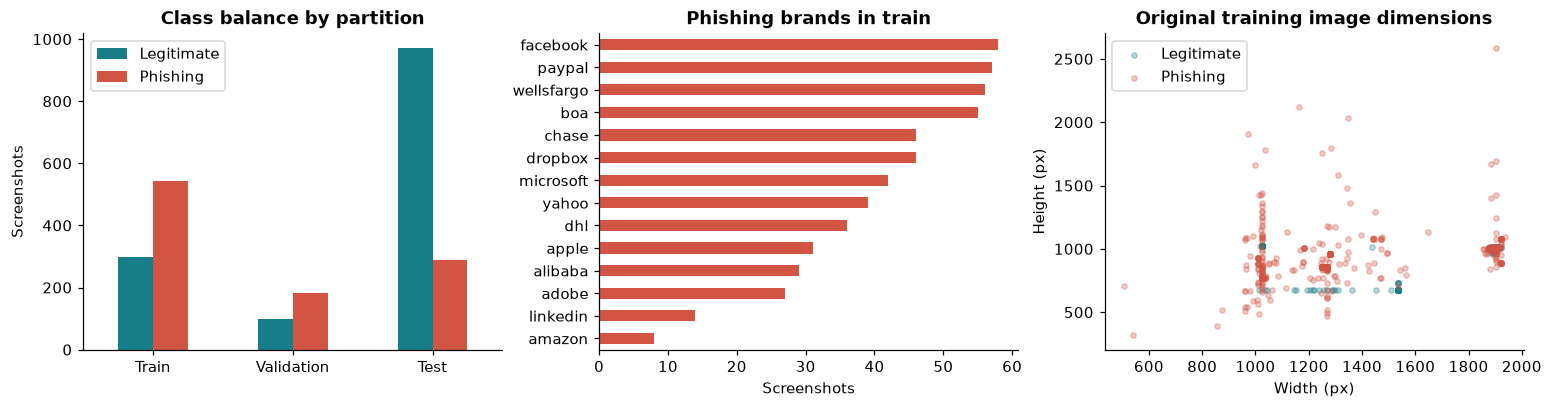

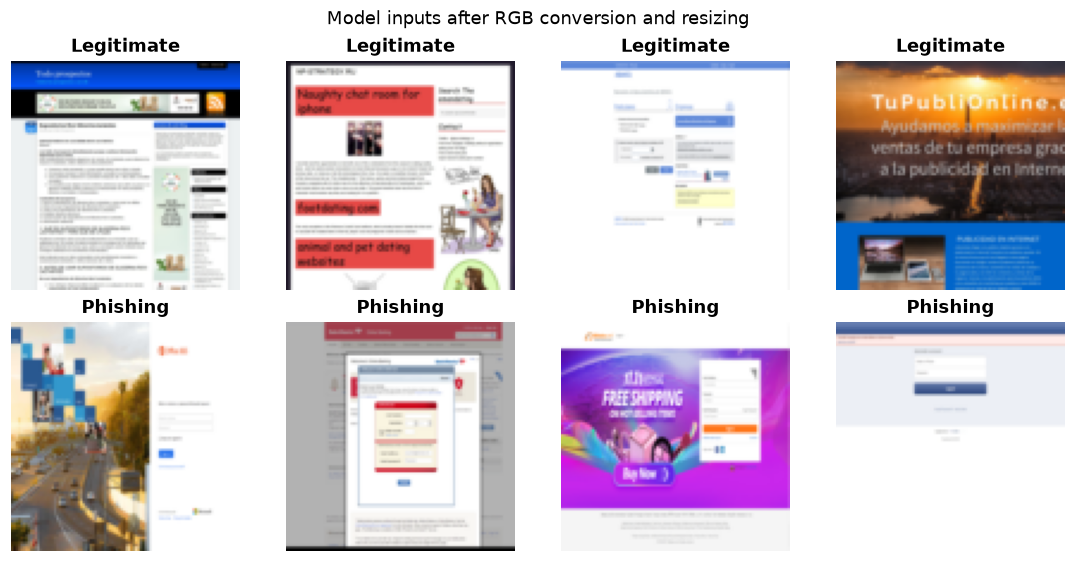

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), layout="constrained")
split_counts[CLASS_NAMES].plot.bar(ax=axes[0], color=COLORS, rot=0)
axes[0].set(title="Class balance by partition", xlabel="", ylabel="Screenshots")
train_frame = decoded.loc[train_idx]
train_frame.loc[train_frame.label.eq(1), "category"].value_counts().sort_values().plot.barh(
    ax=axes[1], color=COLORS[1]
)
axes[1].set(title="Phishing brands in train", xlabel="Screenshots", ylabel="")
for label, color in enumerate(COLORS):
    rows = train_frame[train_frame.label.eq(label)]
    axes[2].scatter(rows.width, rows.height, s=12, alpha=0.30, color=color, label=CLASS_NAMES[label])
axes[2].set(title="Original training image dimensions", xlabel="Width (px)", ylabel="Height (px)")
axes[2].legend()
plt.show()

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 4, figsize=(10, 5), layout="constrained")
for label, row in enumerate(axes):
    examples = rng.choice(train_idx[y[train_idx] == label], size=4, replace=False)
    for ax, index in zip(row, examples):
        ax.imshow(thumbnails[index])
        ax.set_title(CLASS_NAMES[label])
        ax.axis("off")
fig.suptitle("Model inputs after RGB conversion and resizing")
plt.show()

## 3 · Feature engineering and selection

Classical models receive global RGB histograms and 4 × 4 spatial measurements. Each tile summarizes color mean and spread, edge strength, and near-white pixel share. The tile position preserves coarse layout. Use the full descriptor as the reference, then compare two independently selected subsets of 40 features.

**Mutual information** ranks each feature by how much information it carries about the class. **Random forest importance** ranks features by how much they reduce impurity in a train-only forest. The selectors fit on training data. Logistic regression scales each selected feature using training means and standard deviations. The tree models use the original descriptor units.

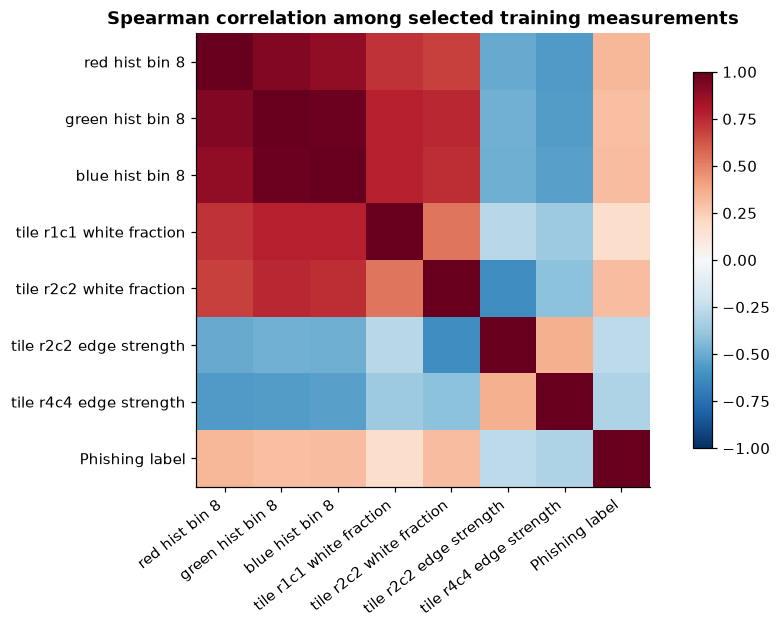

152 original features, 40 in each selected subset.


,Mutual information,Random forest importance
0,tile_r4c1_blue_std,green_hist_bin_6
1,tile_r3c1_blue_mean,red_hist_bin_2
2,green_hist_bin_6,tile_r4c3_edge_strength
3,tile_r4c1_blue_mean,green_hist_bin_5
4,blue_hist_bin_4,tile_r4c1_green_std
5,tile_r2c3_green_mean,red_hist_bin_1
6,tile_r4c1_green_std,blue_hist_bin_8
7,green_hist_bin_5,tile_r4c1_red_std
8,tile_r4c2_red_mean,blue_hist_bin_6
9,tile_r4c1_green_mean,tile_r4c1_blue_std


In [8]:
def visual_features(images):
    """Return global color histograms and 16 tiles of local visual measurements."""
    images = images.astype(np.float32) / 255.0
    columns, names = [], []
    for channel, channel_name in enumerate(("red", "green", "blue")):
        bins = np.minimum((images[..., channel] * 8).astype(np.int8), 7)
        for bin_number in range(8):
            columns.append((bins == bin_number).mean(axis=(1, 2)))
            names.append(f"{channel_name}_hist_bin_{bin_number + 1}")

    tile_side = IMAGE_SIDE // 4
    for row in range(4):
        for column in range(4):
            tile = images[:, row * tile_side:(row + 1) * tile_side,
                          column * tile_side:(column + 1) * tile_side]
            prefix = f"tile_r{row + 1}c{column + 1}"
            for channel, channel_name in enumerate(("red", "green", "blue")):
                plane = tile[..., channel]
                columns.extend([plane.mean(axis=(1, 2)), plane.std(axis=(1, 2))])
                names.extend([f"{prefix}_{channel_name}_mean", f"{prefix}_{channel_name}_std"])
            gray = tile @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
            edge_strength = (
                np.abs(np.diff(gray, axis=1)).mean(axis=(1, 2))
                + np.abs(np.diff(gray, axis=2)).mean(axis=(1, 2))
            ) / 2
            columns.extend([edge_strength, (tile.min(axis=-1) > 0.92).mean(axis=(1, 2))])
            names.extend([f"{prefix}_edge_strength", f"{prefix}_white_fraction"])
    return np.stack(columns, axis=1).astype(np.float32), names


features, feature_names = visual_features(thumbnails)
assert np.isfinite(features[all_indices]).all()
feature_frame = pd.DataFrame(features[train_idx], columns=feature_names)
feature_frame["Phishing label"] = y[train_idx]
correlation_columns = [
    "red_hist_bin_8", "green_hist_bin_8", "blue_hist_bin_8", "tile_r1c1_white_fraction",
    "tile_r2c2_white_fraction", "tile_r2c2_edge_strength", "tile_r4c4_edge_strength",
    "Phishing label",
]
correlation = feature_frame[correlation_columns].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 5.6), layout="constrained")
plot = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
short_names = [name.replace("_", " ") for name in correlation_columns]
ax.set_xticks(np.arange(len(short_names)), short_names, rotation=38, ha="right")
ax.set_yticks(np.arange(len(short_names)), short_names)
ax.set_title("Spearman correlation among selected training measurements")
fig.colorbar(plot, ax=ax, shrink=0.83)
plt.show()


def mutual_information(x, labels):
    return mutual_info_classif(x, labels, random_state=SEED)


mi_selector = SelectKBest(mutual_information, k=40).fit(features[train_idx], y[train_idx])
rf_selector = RandomForestClassifier(
    n_estimators=160, class_weight="balanced", min_samples_leaf=3,
    random_state=SEED, n_jobs=CPU_THREADS,
).fit(features[train_idx], y[train_idx])
rf_columns = np.sort(np.argsort(-rf_selector.feature_importances_, kind="stable")[:40])
feature_sets = {
    "All": np.arange(features.shape[1]),
    "Mutual information": mi_selector.get_support(indices=True),
    "Random forest importance": rf_columns,
}
selection_table = pd.DataFrame({
    "Mutual information": np.asarray(feature_names)[np.argsort(-mi_selector.scores_)[:10]],
    "Random forest importance": np.asarray(feature_names)[
        np.argsort(-rf_selector.feature_importances_)[:10]
    ],
})
print(f"{features.shape[1]} original features, 40 in each selected subset.")
display(selection_table)

## 4 · Visual signature baseline and classical ML

The rule compares each screenshot's 64-bit difference hash with the training phishing hashes. This hash summarizes local brightness order. A match within the selected Hamming distance triggers an alert. A smaller distance means the signatures agree in more positions. This compact lookup is a screenshot analogue of a traditional signature library. Its score is visual similarity.

The classical models are **logistic regression**, which combines scaled visual measurements linearly, **decision tree**, which learns a sequence of visual thresholds, and **random forest**, which averages multiple trees. Class weights compensate for unequal training counts. Each algorithm tries six feature-set and hyperparameter combinations. Selection uses validation F1, then validation average precision to break ties. The F1-selected decision threshold is also fitted on validation and stays fixed for test.

In [9]:
def pick_threshold(labels, scores, candidates):
    """Maximize validation F1, preferring higher precision and then stricter cutoffs."""
    candidates = np.asarray(candidates)
    positive = scores[:, None] >= candidates[None, :]
    hits = (positive & (labels[:, None] == 1)).sum(axis=0)
    flags = positive.sum(axis=0)
    f1 = 2 * hits / (flags + labels.sum())
    precision = hits / np.maximum(flags, 1)
    best = np.lexsort((candidates, precision, f1))[-1]
    return float(candidates[best]), float(f1[best])


probability_thresholds = np.arange(5, 100, 5) / 100
model_signatures = [image_signature(Image.fromarray(image)) for image in thumbnails]
signature_library = [model_signatures[index] for index in train_idx if y[index] == 1]


def signature_scores(hashes):
    return np.asarray([
        64 - min((query ^ known).bit_count() for known in signature_library)
        for query in hashes
    ])


baseline_validation = signature_scores([model_signatures[index] for index in val_idx])
signature_threshold, signature_f1 = pick_threshold(
    y[val_idx], baseline_validation, np.arange(65)
)
print(f"Signature rule: flag if nearest phishing hash is within {64-int(signature_threshold)} bits.")
print(f"Validation F1: {signature_f1:.3f}")

ml_grid = {
    "Logistic regression": [("C", 0.1), ("C", 1.0)],
    "Decision tree": [("max_depth", 5), ("max_depth", 12)],
    "Random forest": [("min_samples_leaf", 1), ("min_samples_leaf", 4)],
}


def build_classifier(name, settings):
    if name == "Logistic regression":
        return Pipeline([
            ("scale", StandardScaler()),
            ("predict", LogisticRegression(
                max_iter=1000, class_weight="balanced", random_state=SEED, **settings
            )),
        ])
    if name == "Decision tree":
        return DecisionTreeClassifier(
            min_samples_leaf=5, class_weight="balanced", random_state=SEED, **settings
        )
    return RandomForestClassifier(
        n_estimators=200, n_jobs=CPU_THREADS, class_weight="balanced",
        random_state=SEED, **settings,
    )


ml_trials, ml_finalists = [], {}
for name, settings in ml_grid.items():
    best_key = (-1, -1)
    for subset, columns in feature_sets.items():
        for parameter, value in settings:
            classifier = build_classifier(name, {parameter: value})
            started = time.perf_counter()
            classifier.fit(features[train_idx][:, columns], y[train_idx])
            elapsed = time.perf_counter() - started
            scores = classifier.predict_proba(features[val_idx][:, columns])[:, 1]
            threshold, val_f1 = pick_threshold(y[val_idx], scores, probability_thresholds)
            val_ap = average_precision_score(y[val_idx], scores)
            trial = {
                "model": name, "features": subset, "parameter": f"{parameter}={value}",
                "validation_f1": val_f1, "validation_ap": val_ap,
                "threshold": threshold, "fit_seconds": elapsed,
            }
            ml_trials.append(trial)
            if (val_f1, val_ap) > best_key:
                best_key = val_f1, val_ap
                ml_finalists[name] = {**trial, "estimator": classifier, "columns": columns}

ml_search = pd.DataFrame(ml_trials)
feature_comparison = ml_search.pivot_table(
    index="model", columns="features", values="validation_f1", aggfunc="max",
)
display(feature_comparison.style.format("{:.3f}"))
display(pd.DataFrame(ml_finalists.values()).drop(columns=["estimator", "columns"]).round(3))

Signature rule: flag if nearest phishing hash is within 18 bits.
Validation F1: 0.796


features,All,Mutual information,Random forest importance
model,,,
Decision tree,0.805,0.799,0.823
Logistic regression,0.846,0.848,0.835
Random forest,0.847,0.854,0.831


,model,features,parameter,validation_f1,validation_ap,threshold,fit_seconds
0,Logistic regression,Mutual information,C=0.1,0.848,0.831,0.35,0.007
1,Decision tree,Random forest importance,max_depth=12,0.823,0.803,0.05,0.011
2,Random forest,Mutual information,min_samples_leaf=1,0.854,0.873,0.35,0.209


## 5 · Deep learning on screenshot pixels

| Architecture | Input and design | Why include it |
|---|---|---|
| Pixel MLP | Pools RGB input to 24 × 24, flattens it, then applies two dense layers. | Tests how much coarse appearance is captured without a convolutional feature extractor. |
| Compact CNN | Three Conv–BatchNorm–ReLU stages, pooling, and a classifier over a 4 × 4 spatial grid. | Preserves where visual patterns appear while learning local shapes and textures. |
| Residual CNN | Three stages with shortcut connections and a 4 × 4 spatial head. | Tests whether a deeper network with residual connections improves the comparison. |

All networks use ReLU, binary cross-entropy with logits, AdamW, a train-derived positive-class weight, and two learning-rate and regularization settings. Early stopping monitors validation average precision, which summarizes a model's precision and recall across cutoffs. Select the saved checkpoint for each architecture by validation F1 and then average precision. No pretrained weights are required.

In [10]:
class PixelMLP(nn.Module):
    def __init__(self, dropout):
        super().__init__()
        self.network = nn.Sequential(
            nn.AdaptiveAvgPool2d((24, 24)), nn.Flatten(),
            nn.Linear(3 * 24 * 24, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


def build_network(name, dropout):
    if name == "Pixel MLP":
        return PixelMLP(dropout)
    return ScreenshotCNN(dropout, residual=(name == "Residual CNN"))


pixels = to_tensor(thumbnails)
positive_weight = float(np.sum(y[train_idx] == 0) / np.sum(y[train_idx] == 1))
loss_function = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(positive_weight, device=DEVICE))


def make_loader(indices, shuffle=False):
    dataset = TensorDataset(pixels[indices], torch.tensor(y[indices], dtype=torch.float32))
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
        generator=torch.Generator().manual_seed(SEED),
    )


@torch.inference_mode()
def dataset_scores(model, loader):
    model.eval()
    scores, total_loss, count = [], 0.0, 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        scores.append(logits.sigmoid().cpu().numpy())
        total_loss += loss_function(logits, labels).item() * len(labels)
        count += len(labels)
    return np.concatenate(scores), total_loss / count


def fit_network(name, settings):
    torch.manual_seed(SEED)
    model = build_network(name, settings["dropout"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=settings["lr"], weight_decay=1e-4)
    training = make_loader(train_idx, shuffle=True)
    validation = make_loader(val_idx)
    history, best_ap, stale_epochs = [], -1.0, 0
    started = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0.0
        for images, labels in training:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = loss_function(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)
        val_scores, val_loss = dataset_scores(model, validation)
        val_ap = average_precision_score(y[val_idx], val_scores)
        history.append({
            "epoch": epoch, "train_loss": total_loss / len(train_idx),
            "val_loss": val_loss, "val_ap": val_ap,
        })
        if val_ap > best_ap + 1e-5:
            best_ap, best_epoch, stale_epochs = val_ap, epoch, 0
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        else:
            stale_epochs += 1
        if stale_epochs >= PATIENCE:
            break
    model.load_state_dict(best_state)
    scores, _ = dataset_scores(model, validation)
    threshold, val_f1 = pick_threshold(y[val_idx], scores, probability_thresholds)
    return {
        "model": name, **settings, "validation_f1": val_f1,
        "validation_ap": average_precision_score(y[val_idx], scores),
        "threshold": threshold, "best_epoch": best_epoch,
        "fit_seconds": time.perf_counter() - started,
        "parameters": sum(parameter.numel() for parameter in model.parameters()),
        "network": model, "history": history,
    }

Pixel MLP | {'lr': 0.001, 'dropout': 0.25} | validation F1 0.803 | best epoch 5 | 0.6 s


Pixel MLP | {'lr': 0.0005, 'dropout': 0.4} | validation F1 0.795 | best epoch 1 | 0.3 s


Compact CNN | {'lr': 0.001, 'dropout': 0.25} | validation F1 0.837 | best epoch 4 | 2.9 s


Compact CNN | {'lr': 0.0005, 'dropout': 0.4} | validation F1 0.860 | best epoch 14 | 4.9 s


Residual CNN | {'lr': 0.001, 'dropout': 0.25} | validation F1 0.815 | best epoch 10 | 6.8 s


Residual CNN | {'lr': 0.0005, 'dropout': 0.4} | validation F1 0.828 | best epoch 8 | 5.9 s


,model,lr,dropout,validation_f1,validation_ap,threshold,best_epoch,fit_seconds,parameters
0,Pixel MLP,0.0010,0.25,0.8028,0.8039,0.60,5,0.6064,225473
1,Pixel MLP,0.0005,0.40,0.7946,0.7923,0.55,1,0.3314,225473
2,Compact CNN,0.0010,0.25,0.8371,0.8541,0.45,4,2.8602,53777
3,Compact CNN,0.0005,0.40,0.8601,0.8931,0.55,14,4.8969,53777
4,Residual CNN,0.0010,0.25,0.8148,0.8355,0.05,10,6.8183,95661
5,Residual CNN,0.0005,0.40,0.8276,0.8221,0.30,8,5.8594,95661


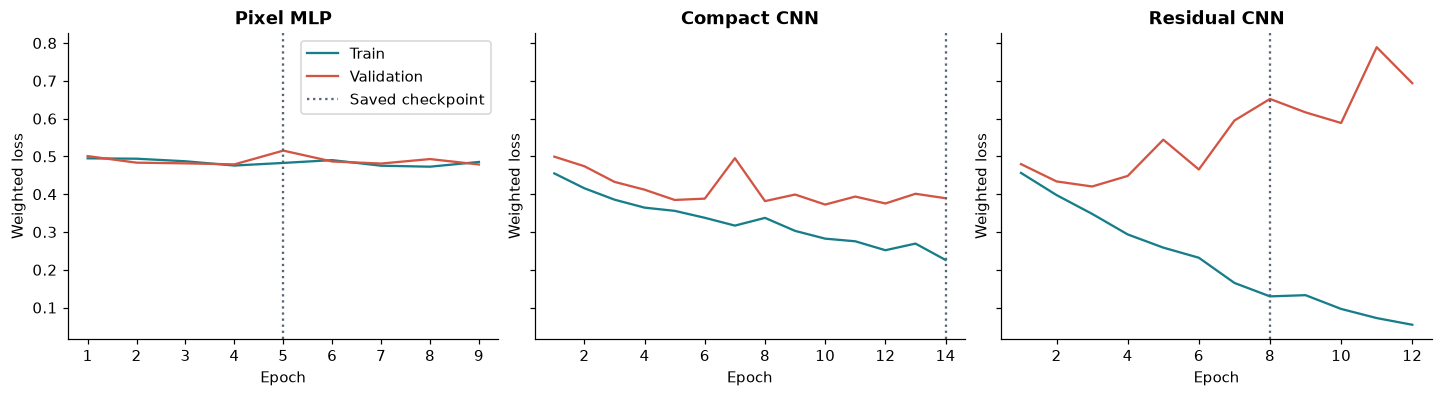

In [11]:
network_settings = [{"lr": 0.001, "dropout": 0.25}, {"lr": 0.0005, "dropout": 0.40}]
dl_trials, dl_finalists = [], {}
for name in ("Pixel MLP", "Compact CNN", "Residual CNN"):
    candidates = []
    for settings in network_settings:
        candidate = fit_network(name, settings)
        candidates.append(candidate)
        dl_trials.append({
            key: value for key, value in candidate.items() if key not in {"network", "history"}
        })
        print(f"{name} | {settings} | validation F1 {candidate['validation_f1']:.3f} "
              f"| best epoch {candidate['best_epoch']} "
              f"| {candidate['fit_seconds']:.1f} s", flush=True)
    dl_finalists[name] = max(
        candidates, key=lambda trial: (trial["validation_f1"], trial["validation_ap"])
    )

dl_search = pd.DataFrame(dl_trials)
display(dl_search.round(4))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), layout="constrained", sharey=True)
for ax, (name, trial) in zip(axes, dl_finalists.items()):
    history = pd.DataFrame(trial["history"])
    ax.plot(history.epoch, history.train_loss, color=COLORS[0], label="Train")
    ax.plot(history.epoch, history.val_loss, color=COLORS[1], label="Validation")
    ax.axvline(trial["best_epoch"], c="#596477", linestyle=":", label="Saved checkpoint")
    ax.set(title=name, xlabel="Epoch", ylabel="Weighted loss")
axes[0].legend()
plt.show()

## 6 · Held-out test results

- **Accuracy** is the share of all screenshots classified correctly.
- **Precision** is the share of alerts that are phishing. Low precision costs analysts time.
- **Recall** is the share of phishing screenshots detected. **False negative rate** is the share missed.
- **False positive rate** is the share of legitimate screenshots incorrectly flagged.
- **F1** balances precision and recall at the chosen cutoff.
- **ROC-AUC** measures how well scores rank phishing above legitimate examples. **Average precision** summarizes the precision–recall curve and is particularly informative when positive examples are uncommon.

The majority-class accuracy is shown for context. One missed phishing page and one incorrect alert can have different consequences even when they contribute equally to accuracy. Validation determines the model configurations and thresholds before the final test comparison. Inference timings are median batch scoring times divided by the test set size. All timings start with decoded, resized RGB data. The shared screenshot decoding and resizing time is excluded. Deep models run on the device printed in the setup.

In [12]:
def timed_scores(score_function):
    durations = []
    for _ in range(3):
        started = time.perf_counter()
        scores = score_function()
        durations.append(time.perf_counter() - started)
    return scores, 1000 * float(np.median(durations)) / len(test_idx)


def compute_metrics(labels, scores, threshold):
    prediction = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, prediction, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(labels, prediction),
        "precision": precision_score(labels, prediction, zero_division=0),
        "recall": recall_score(labels, prediction),
        "f1": f1_score(labels, prediction),
        "fpr": fp / (fp + tn), "fnr": fn / (fn + tp),
        "roc_auc": roc_auc_score(labels, scores),
        "avg_precision": average_precision_score(labels, scores),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
    }


ml_name, ml_best = max(ml_finalists.items(), key=lambda item: (
    item[1]["validation_f1"], item[1]["validation_ap"]
))
dl_name, dl_best = max(dl_finalists.items(), key=lambda item: (
    item[1]["validation_f1"], item[1]["validation_ap"]
))
cnn_name, cnn_best = max(
    ((name, trial) for name, trial in dl_finalists.items() if name != "Pixel MLP"),
    key=lambda item: (item[1]["validation_f1"], item[1]["validation_ap"]),
)
test_scores, test_predictions, metrics_rows = {}, {}, []


def record_result(name, family, scores, threshold, milliseconds, fit_seconds):
    assert np.isfinite(scores).all() and len(scores) == len(test_idx)
    test_scores[name] = scores
    test_predictions[name] = (scores >= threshold).astype(int)
    metrics_rows.append({
        "model": name, "family": family, "threshold": threshold,
        **compute_metrics(y[test_idx], scores, threshold),
        "score_ms_per_image": milliseconds, "fit_seconds": fit_seconds,
    })


test_images = thumbnails[test_idx]
baseline_scores, baseline_ms = timed_scores(
    lambda: signature_scores([image_signature(Image.fromarray(image)) for image in test_images])
)
record_result("Visual signature", "Traditional", baseline_scores, signature_threshold, baseline_ms, 0.0)


def ml_scores(trial, images):
    descriptors, _ = visual_features(images)
    return trial["estimator"].predict_proba(descriptors[:, trial["columns"]])[:, 1]


def dl_scores(trial, images):
    model = trial["network"].eval()
    scores = []
    with torch.inference_mode():
        for batch in to_tensor(images).split(BATCH_SIZE):
            scores.append(model(batch.to(DEVICE)).sigmoid().cpu().numpy())
    return np.concatenate(scores)


for name, trial in ml_finalists.items():
    scores, milliseconds = timed_scores(lambda: ml_scores(trial, test_images))
    record_result(name, "Classical ML", scores, trial["threshold"], milliseconds, trial["fit_seconds"])
for name, trial in dl_finalists.items():
    scores, milliseconds = timed_scores(lambda: dl_scores(trial, test_images))
    record_result(name, "Deep learning", scores, trial["threshold"], milliseconds, trial["fit_seconds"])

results = pd.DataFrame(metrics_rows).set_index("model")
print(f"Test support: {len(test_idx):,}. Majority-class accuracy: "
      f"{np.bincount(y[test_idx]).max() / len(test_idx):.1%}.")
print(f"Validation-selected models: {ml_name} (ML), {dl_name} (DL).")
display(results.round(4))

Test support: 1,260. Majority-class accuracy: 77.0%.
Validation-selected models: Random forest (ML), Compact CNN (DL).


,family,threshold,accuracy,precision,recall,f1,fpr,fnr,roc_auc,avg_precision,tn,fp,fn,tp,score_ms_per_image,fit_seconds
model,,,,,,,,,,,,,,,,
Visual signature,Traditional,46.00,0.4278,0.2776,0.9276,0.4273,0.7216,0.0724,0.7864,0.5554,270,700,21,269,0.0629,0.0000
Logistic regression,Classical ML,0.35,0.6587,0.3943,0.9000,0.5483,0.4134,0.1000,0.8691,0.6859,569,401,29,261,0.9257,0.0067
Decision tree,Classical ML,0.05,0.5698,0.3389,0.9138,0.4944,0.5330,0.0862,0.7578,0.4194,453,517,25,265,0.8317,0.0113
Random forest,Classical ML,0.35,0.6056,0.3633,0.9483,0.5253,0.4969,0.0517,0.8742,0.7010,488,482,15,275,0.8580,0.2085
Pixel MLP,Deep learning,0.60,0.3579,0.2550,0.9310,0.4003,0.8134,0.0690,0.7367,0.4908,181,789,20,270,0.0420,0.6064
Compact CNN,Deep learning,0.55,0.7683,0.4981,0.8931,0.6395,0.2691,0.1069,0.8992,0.7033,709,261,31,259,0.1604,4.8969
Residual CNN,Deep learning,0.30,0.6175,0.3667,0.9103,0.5228,0.4701,0.0897,0.8358,0.5896,514,456,26,264,0.1366,5.8594


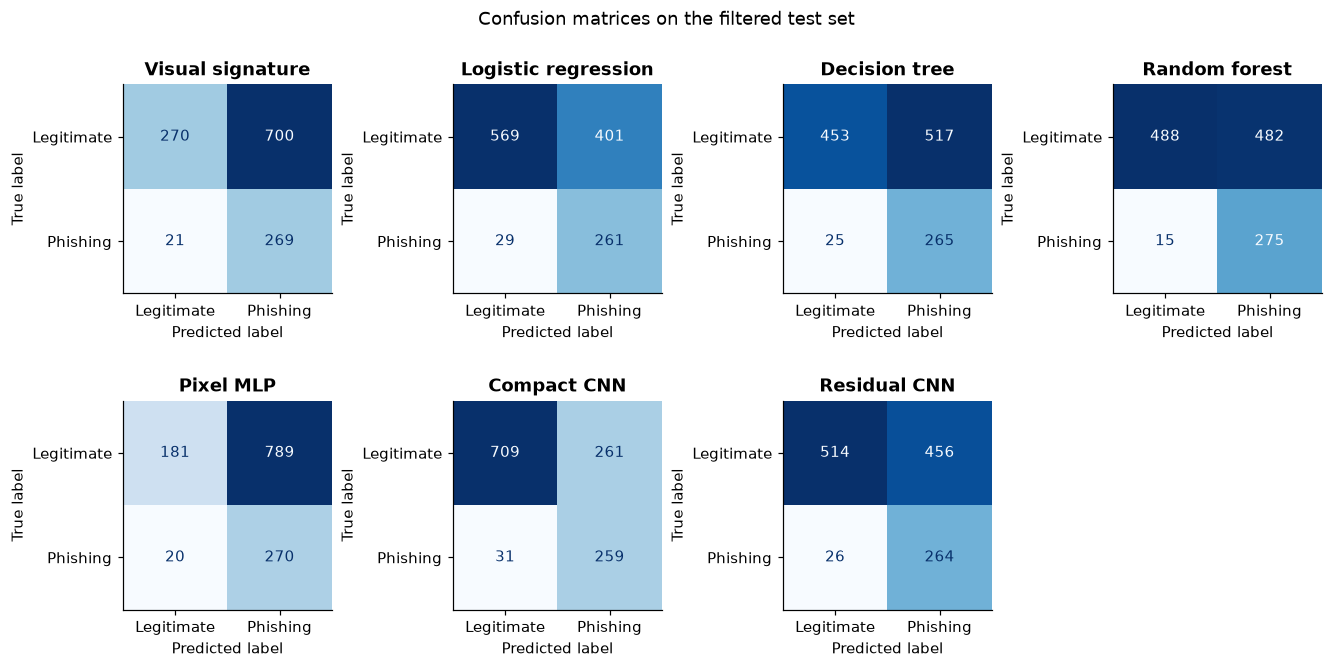

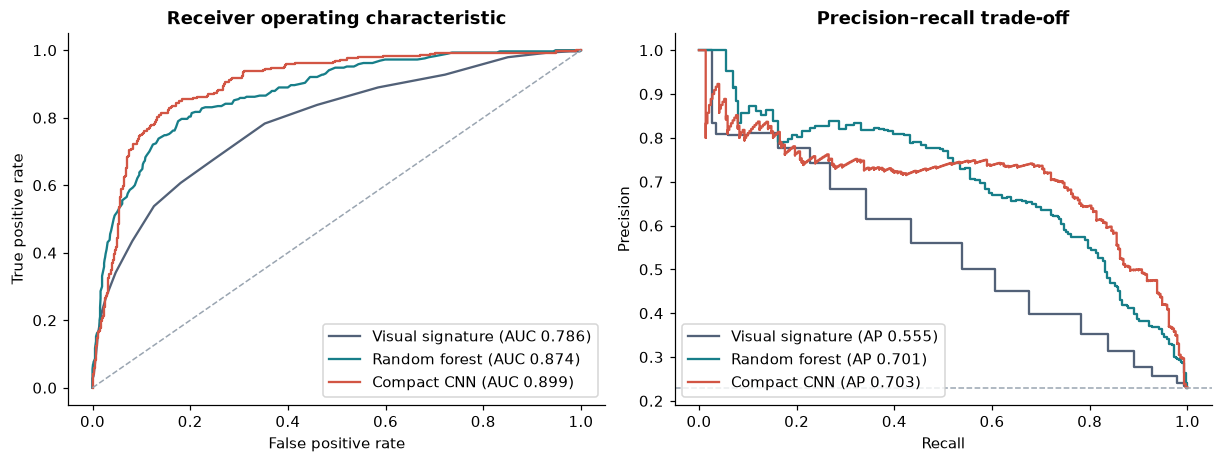

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6), layout="constrained")
for ax, (name, predictions) in zip(axes.flat, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y[test_idx], predictions, labels=[0, 1], display_labels=CLASS_NAMES,
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(name)
axes.flat[-1].axis("off")
fig.suptitle("Confusion matrices on the filtered test set")
fig.savefig(RUN_DIR / "confusion_matrices.png", dpi=160)
plt.show()

chosen_names = ["Visual signature", ml_name, dl_name]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")
for name, color in zip(chosen_names, ["#526178", "#177E89", "#D25544"]):
    false_positive, true_positive, _ = roc_curve(y[test_idx], test_scores[name])
    precision, recall, _ = precision_recall_curve(y[test_idx], test_scores[name])
    axes[0].plot(false_positive, true_positive, color=color,
                 label=f"{name} (AUC {results.loc[name, 'roc_auc']:.3f})")
    axes[1].step(recall, precision, where="post", color=color,
                 label=f"{name} (AP {results.loc[name, 'avg_precision']:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="#9AA5B1", linewidth=1)
axes[1].axhline(y[test_idx].mean(), linestyle="--", color="#9AA5B1", linewidth=1)
axes[0].set(title="Receiver operating characteristic", xlabel="False positive rate",
            ylabel="True positive rate")
axes[1].set(title="Precision–recall trade-off", xlabel="Recall", ylabel="Precision")
axes[0].legend(loc="lower right")
axes[1].legend(loc="lower left")
fig.savefig(RUN_DIR / "roc_and_precision_recall.png", dpi=160)
plt.show()

## 7 · Explaining model decisions

**Grad-CAM** highlights spatial activations that support the displayed prediction in the selected CNN. Warmer areas contribute more positive evidence for the target score. **Occlusion** replaces one patch at a time with the mean RGB color of the training images. Red patches lower the displayed class score when covered. Blue patches increase it. Occlusion uses the score change in logit units so it can show effects even when sigmoid scores are close to zero or one. Both methods explain model behavior on a given image. They may emphasize a background or empty area because the model can learn collection artifacts. [Grad-CAM paper](https://arxiv.org/abs/1610.02391) · [Occlusion method in Visualizing and Understanding Convolutional Networks](https://arxiv.org/abs/1311.2901)

The examples include a correct phishing decision, a correct legitimate decision, and the first available error of each type. The displayed score is a model output. It has not been calibrated to estimate real-world phishing risk.

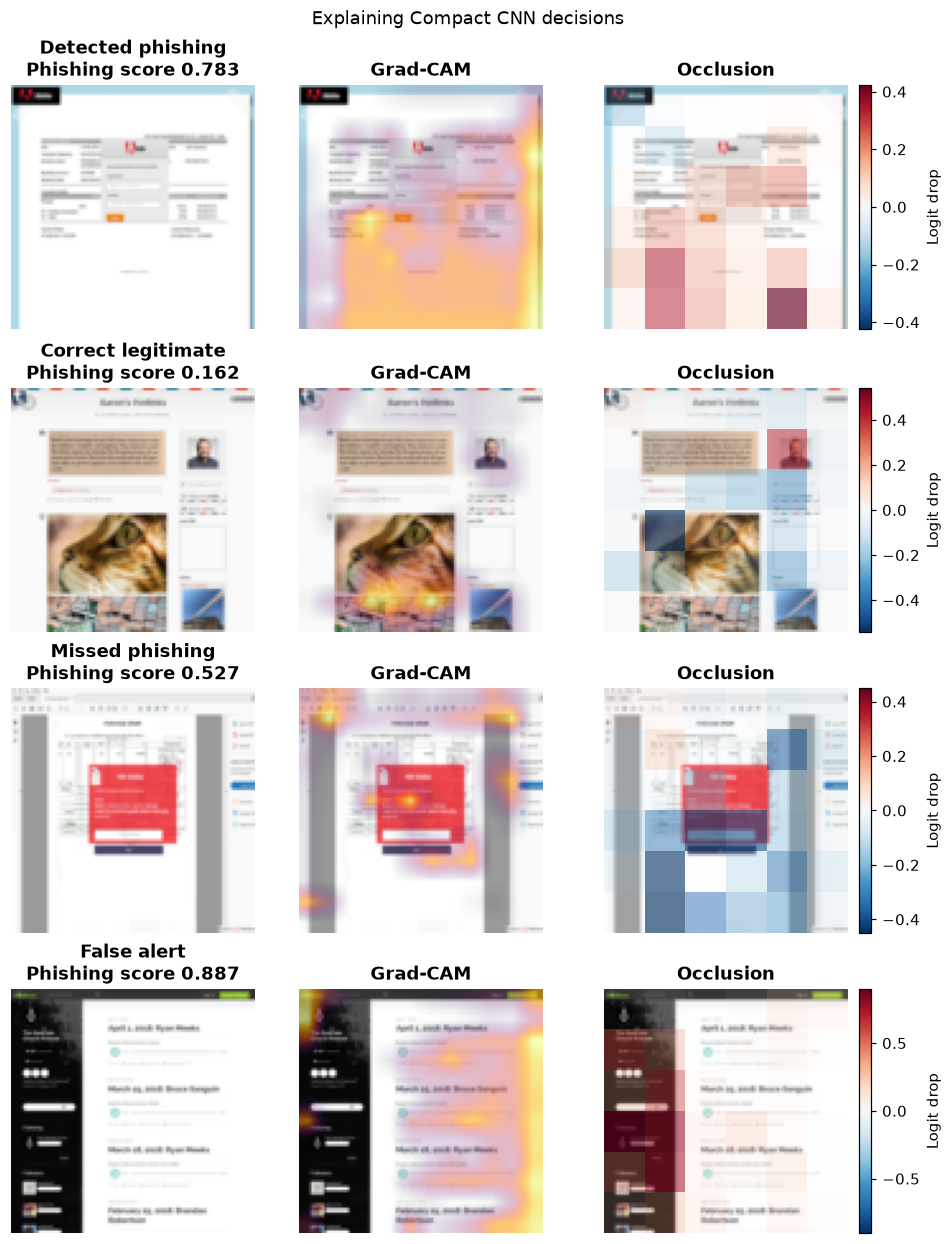

,case,actual,prediction,phishing score,largest occlusion drop,"patch (row, column from top left)"
0,Detected phishing,Phishing,Phishing,0.783,0.424,"(6, 5) of 6 × 6"
1,Correct legitimate,Legitimate,Legitimate,0.162,0.421,"(2, 5) of 6 × 6"
2,Missed phishing,Phishing,Legitimate,0.527,0.173,"(2, 2) of 6 × 6"
3,False alert,Legitimate,Phishing,0.887,0.901,"(4, 1) of 6 × 6"


In [14]:
def grad_cam(model, image, target):
    """Weight the final spatial channels by gradients for the selected class."""
    model.eval()
    activation = model.encoder(to_tensor(image[None]).to(DEVICE))
    logit = model.classify_features(activation)
    target_logit = logit if target == 1 else -logit
    gradients, = torch.autograd.grad(target_logit.sum(), activation)
    weights = gradients.mean(dim=(2, 3), keepdim=True)
    heatmap = (weights * activation).sum(dim=1, keepdim=True).clamp(min=0)
    heatmap = F.interpolate(heatmap, size=image.shape[:2], mode="bilinear", align_corners=False)
    heatmap = heatmap[0, 0].detach().cpu().numpy()
    return heatmap / max(float(heatmap.max()), 1e-8)


background = thumbnails[train_idx].mean(axis=(0, 1, 2)).round().astype(np.uint8)


@torch.inference_mode()
def occlusion_map(model, image, target, grid=6):
    """Measure the selected-class logit lost when each patch is covered."""
    bounds = np.linspace(0, IMAGE_SIDE, grid + 1, dtype=int)
    masked = np.repeat(image[None], grid * grid, axis=0)
    for row in range(grid):
        for column in range(grid):
            masked[row * grid + column, bounds[row]:bounds[row + 1],
                   bounds[column]:bounds[column + 1]] = background
    original = model(to_tensor(image[None]).to(DEVICE)).item()
    occluded = model(to_tensor(masked).to(DEVICE)).cpu().numpy()
    direction = 1 if target == 1 else -1
    return (direction * (original - occluded)).reshape(grid, grid)


cnn = cnn_best["network"].eval()
cnn_predictions = test_predictions[cnn_name]
case_types = {
    "Detected phishing": (1, 1), "Correct legitimate": (0, 0),
    "Missed phishing": (1, 0), "False alert": (0, 1),
}
cases = {}
for title, (actual, prediction) in case_types.items():
    matches = np.flatnonzero((y[test_idx] == actual) & (cnn_predictions == prediction))
    if len(matches):
        cases[title] = matches[0]

fig, axes = plt.subplots(len(cases), 3, figsize=(8.7, 2.8 * len(cases)),
                        layout="constrained", squeeze=False)
explanations = []
for ax_row, (title, position) in zip(axes, cases.items()):
    image = test_images[position]
    predicted = int(cnn_predictions[position])
    score = test_scores[cnn_name][position]
    cam = grad_cam(cnn, image, predicted)
    occlusion = occlusion_map(cnn, image, predicted)
    for ax in ax_row:
        ax.imshow(image)
        ax.axis("off")
    ax_row[0].set_title(f"{title}\nPhishing score {score:.3f}")
    ax_row[1].set_title("Grad-CAM")
    ax_row[1].imshow(cam, cmap="inferno", vmin=0, vmax=1, alpha=0.72 * cam)
    limit = max(np.abs(occlusion).max(), 1e-5)
    extent = (-0.5, IMAGE_SIDE - 0.5, IMAGE_SIDE - 0.5, -0.5)
    ax_row[2].set_title("Occlusion")
    layer = ax_row[2].imshow(occlusion, cmap="RdBu_r", vmin=-limit, vmax=limit,
                             alpha=0.65 * np.abs(occlusion) / limit, extent=extent,
                             interpolation="nearest")
    fig.colorbar(layer, ax=ax_row[2], fraction=0.046, pad=0.04, label="Logit drop")
    row, column = np.unravel_index(np.argmax(occlusion), occlusion.shape)
    explanations.append({
        "case": title, "actual": CLASS_NAMES[y[test_idx[position]]],
        "prediction": CLASS_NAMES[predicted], "phishing score": float(score),
        "largest occlusion drop": float(occlusion[row, column]),
        "patch (row, column from top left)": f"({row + 1}, {column + 1}) of 6 × 6",
    })
fig.suptitle(f"Explaining {cnn_name} decisions")
fig.savefig(RUN_DIR / "cnn_explanations.png", dpi=160)
plt.show()
explanation_table = pd.DataFrame(explanations)
display(explanation_table.round(3))

### What the saved explanations show

In the saved CPU run, covering a mostly white patch near the bottom right of the detected phishing screenshot reduced the phishing score the most. In the correct legitimate example, covering an upper-right patch reduced support for the legitimate decision. In the false alert, covering part of the dark left sidebar reduced support for phishing more than any other patch. These examples show how layout and background can influence decisions, even when a reviewer would pay more attention to the form or logo.

### Which visual measurements helped the classical model

Permutation importance shuffles each input feature in the validation set and measures the change in average precision. A larger drop indicates stronger reliance on that feature. Correlated features can share information, so each bar is a model-specific measurement. The bars use five repeats and show one standard deviation. [Scikit-learn permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)

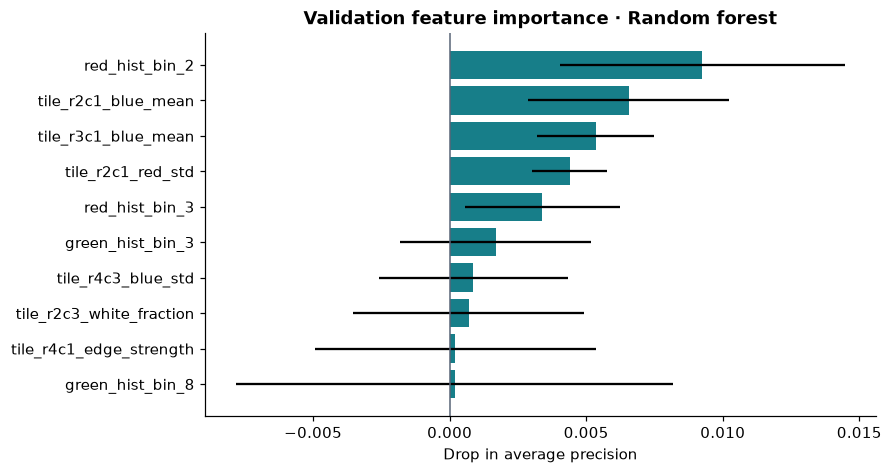

In [15]:
columns = ml_best["columns"]
permutation = permutation_importance(
    ml_best["estimator"], features[val_idx][:, columns], y[val_idx],
    scoring="average_precision", n_repeats=5, random_state=SEED,
)
rank = np.argsort(permutation.importances_mean)[-10:]
fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.barh(np.asarray(feature_names)[columns][rank],
        permutation.importances_mean[rank], xerr=permutation.importances_std[rank],
        color=COLORS[0])
ax.axvline(0, color="#596477", linewidth=1)
ax.set(title=f"Validation feature importance · {ml_name}", xlabel="Drop in average precision")
fig.savefig(RUN_DIR / "feature_importance.png", dpi=160)
plt.show()

## 8 · Comparative analysis and limitations

Signature matching is simple to inspect and update with additional reference images. Scoring time grows with the number of stored hashes in this implementation. Tree models express visual decisions as thresholds. Random forests combine many trees and use more computation. CNNs can learn local visual patterns from pixels, with a training cost and less direct interpretability. Grad-CAM and occlusion make individual CNN decisions easier to review. Models would need re-evaluation on new screenshots and fresh labels as website designs and traffic change.

Phish-IRIS is a useful visual benchmark with a limited collection period and a curated set of impersonated brands. A score can reflect screenshot capture conditions, page layout or the composition of the legitimate class. The split does not establish unseen-domain or unseen-brand performance. Candidate and alert volumes in live traffic will differ from this experiment. Treat the output as a screening signal and validate it against a newer, domain- and time-grouped collection before operational use.

In [16]:
comparison = results.loc[chosen_names, [
    "accuracy", "precision", "recall", "f1", "roc_auc", "fpr", "fnr",
    "fp", "fn", "score_ms_per_image", "fit_seconds",
]]
display(comparison.round(4))
for name, row in comparison.iterrows():
    print(f"{name}: F1 {row.f1:.3f}. "
          f"{int(row.fp)} legitimate pages flagged and {int(row.fn)} phishing pages missed.")

test_brands = decoded.loc[test_idx, ["category", "label"]].copy()
test_brands["cnn_flag"] = test_predictions[cnn_name]
brand_recall = test_brands.loc[test_brands.label.eq(1)].groupby("category").cnn_flag.agg(
    screenshots="size", detected="sum", recall="mean"
).sort_values("screenshots", ascending=False)
print(f"Recall by targeted brand for {cnn_name}. Small groups give noisy estimates.")
display(brand_recall.round(3))

,accuracy,precision,recall,f1,roc_auc,fpr,fnr,fp,fn,score_ms_per_image,fit_seconds
model,,,,,,,,,,,
Visual signature,0.4278,0.2776,0.9276,0.4273,0.7864,0.7216,0.0724,700,21,0.0629,0.0000
Random forest,0.6056,0.3633,0.9483,0.5253,0.8742,0.4969,0.0517,482,15,0.8580,0.2085
Compact CNN,0.7683,0.4981,0.8931,0.6395,0.8992,0.2691,0.1069,261,31,0.1604,4.8969


Visual signature: F1 0.427. 700 legitimate pages flagged and 21 phishing pages missed.
Random forest: F1 0.525. 482 legitimate pages flagged and 15 phishing pages missed.
Compact CNN: F1 0.640. 261 legitimate pages flagged and 31 phishing pages missed.
Recall by targeted brand for Compact CNN. Small groups give noisy estimates.


,screenshots,detected,recall
category,,,
paypal,65,59,0.908
microsoft,33,26,0.788
facebook,32,30,0.938
dhl,22,20,0.909
dropbox,21,20,0.952
chase,20,18,0.900
yahoo,18,17,0.944
wellsfargo,18,13,0.722
alibaba,14,12,0.857


### What the saved test results show

The compact CNN had the highest test F1 at **0.640**, up from **0.427** for the visual signature rule. It cut false alerts from **700 to 261** and missed **31 phishing pages** compared with **21** for the rule. The validation-selected random forest had the fewest misses at **15**, with **482 false alerts**. Which trade-off is preferable depends on how much analyst time is available and how costly a missed threat would be.

The CNN reached **76.8% accuracy**, close to the **77.0%** obtained by labeling every screenshot legitimate. The accuracy figures tell two very different stories. The majority-class rule would miss all **290** phishing pages, while the CNN detected **259**. Phishing made up **64.5%** of validation and **23.0%** of test. That shift is one reason to read precision and false alerts alongside recall. These results describe the saved benchmark run under validation-selected cutoffs.

Precision also depends on prevalence. At the **23.0%** test share, **49.8%** of the CNN's alerts were correct. Applying its **89.3%** recall and **26.9%** false-positive rate to a stream that is only **1%** phishing would leave only about **3.2%** of alerts pointing to real phishing, so most analyst review would go to legitimate pages. The cutoff was selected at **64.5%** validation prevalence, and the saved scores are uncalibrated ranking scores, not probabilities. A deployment should tune the operating point on realistic prevalence and estimate alert volume and review cost.


## 9 · Demo and saved experiment files

For a quick demonstration, start with the screenshot examples in section 2. Use the confusion matrices to explain the difference between a missed threat and a false alert. Then show one screenshot and its two heatmaps from section 7. The walkthrough below uses a benchmark image first. To try your own PNG or JPEG, point `DEMO_IMAGE` at a local image and rerun the cell.

`phish_iris_run/` keeps the result tables and the selected CNN checkpoint used in this report. Running the notebook from start to finish regenerates the charts, split manifest and fitted classical model.


Benchmark example. Dataset label: Phishing
Compact CNN: Phishing (score 0.783, cutoff 0.55)


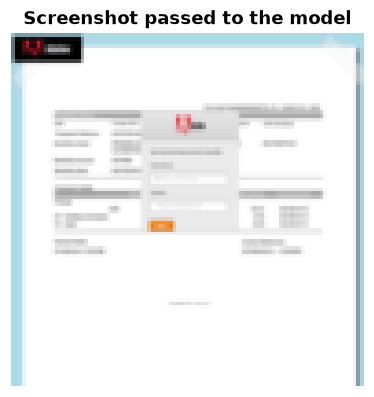

In [17]:
def predict_screenshot(image, trial=cnn_best):
    """Score a local screenshot with the validation-selected convolutional model."""
    if isinstance(image, (str, Path)):
        with Image.open(image) as source:
            image = as_model_image(to_rgb(source))
    score = float(dl_scores(trial, image[None])[0])
    return {"prediction": CLASS_NAMES[int(score >= trial["threshold"])],
            "phishing_score": score, "cutoff": trial["threshold"]}


DEMO_IMAGE = None  # Example: Path("my_screenshot.png")
if DEMO_IMAGE is None:
    demo_index = int(test_idx[np.flatnonzero(y[test_idx] == 1)[0]])
    demo_pixels = thumbnails[demo_index]
    print("Benchmark example. Dataset label:", CLASS_NAMES[y[demo_index]])
else:
    with Image.open(DEMO_IMAGE) as source:
        demo_pixels = as_model_image(to_rgb(source))

demo_prediction = predict_screenshot(demo_pixels)
print(f'{cnn_name}: {demo_prediction["prediction"]} '
      f'(score {demo_prediction["phishing_score"]:.3f}, cutoff {demo_prediction["cutoff"]:.2f})')
fig, ax = plt.subplots(figsize=(3.5, 3.5), layout="constrained")
ax.imshow(demo_pixels)
ax.set_title("Screenshot passed to the model")
ax.axis("off")
plt.show()

In [18]:
results.to_csv(RUN_DIR / "test_metrics.csv")
ml_search.to_csv(RUN_DIR / "ml_validation_search.csv", index=False)
dl_search.to_csv(RUN_DIR / "dl_validation_search.csv", index=False)
split_counts.to_csv(RUN_DIR / "split_counts.csv")
brand_recall.to_csv(RUN_DIR / "cnn_brand_recall.csv")
explanation_table.to_csv(RUN_DIR / "explained_predictions.csv", index=False)
pd.concat([
    decoded.loc[indices, ["category", "label", "source_split", "pixel_hash"]]
    .assign(split=name, group=group_by_image.loc[indices])
    for name, indices in splits.items()
]).to_csv(RUN_DIR / "split_manifest.csv", index=False)

joblib.dump({
    "name": ml_name, "estimator": ml_best["estimator"], "columns": ml_best["columns"],
    "feature_names": feature_names, "threshold": ml_best["threshold"], "image_side": IMAGE_SIDE,
}, RUN_DIR / "selected_ml.joblib")
torch.save({
    "name": cnn_name, "dropout": cnn_best["dropout"], "threshold": cnn_best["threshold"],
    "image_side": IMAGE_SIDE, "state_dict": {key: value.cpu() for key, value in cnn.state_dict().items()},
}, RUN_DIR / "selected_cnn.pt")
(RUN_DIR / "experiment.json").write_text(json.dumps({
    "dataset_url": DATA_URL, "dataset_md5": ARCHIVE_MD5, "seed": SEED,
    "versions": versions, "data_audit": data_audit, "selected_ml": ml_name,
    "selected_dl": dl_name, "selected_cnn": cnn_name,
    "feature_sets": {name: [feature_names[i] for i in cols] for name, cols in feature_sets.items()},
}, indent=2), encoding="utf-8")
print("Saved test metrics, validation searches, split counts, explanations and the selected CNN in", RUN_DIR.name)

Saved test metrics, validation searches, split counts, explanations and the selected CNN in phish_iris_run


## References

- Dalgic, Bozkir and Aydos. *Phish-IRIS: A New Approach for Vision Based Brand Prediction of Phishing Web Pages via Compact Visual Descriptors*. [Paper](https://arxiv.org/abs/1905.07767)
- Bozkir and Dalgic. *Phish-Iris Dataset*, Version 1. [Original dataset](https://data.mendeley.com/datasets/tk4fkswtj5/1) · [Zenodo archive used here](https://zenodo.org/records/23477065)
- Scarfone and Mell. *Guide to Intrusion Detection and Prevention Systems*. [NIST SP 800-94](https://csrc.nist.gov/pubs/sp/800/94/final)
- Lin et al. *Phishpedia: A Hybrid Deep Learning Based Approach to Visually Identify Phishing Webpages*. [USENIX Security 2021](https://www.usenix.org/conference/usenixsecurity21/presentation/lin)
- Selvaraju et al. *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*. [Paper](https://arxiv.org/abs/1610.02391)
- Zeiler and Fergus. *Visualizing and Understanding Convolutional Networks*. [Paper](https://arxiv.org/abs/1311.2901)
- Libraries. [PyTorch](https://pytorch.org/docs/stable/index.html) · [Scikit-learn](https://scikit-learn.org/stable/) · [Pillow](https://pillow.readthedocs.io/) · [NumPy](https://numpy.org/doc/) · [Pandas](https://pandas.pydata.org/docs/) · [Matplotlib](https://matplotlib.org/stable/) · [Joblib](https://joblib.readthedocs.io/)